# Data Science & AI/ML — Practical Exam (Set A: Campaign Response)
## Section A — Technical Work (Tasks 1 to 5)

**Student name:** Isamaliya Ayush |  **Student ID:** 11225  |  **Set:** A


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Dataset

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
rng = np.random.default_rng(404)
n = 300
cols = ['visits', 'recency', 'engagement', 'spend']
x = rng.normal(size=(n, 4))
group = rng.choice(["G1", "G2"], size=n)
score = x @ np.array([0.6, -0.9, 1.1, 0.4])
score += 0.4 * (group == "G2") + rng.normal(0, 1, n)
y = (score > 0).astype(int)
df = pd.DataFrame(np.round(50 + 10*x, 2), columns=cols)
df.insert(0, "record_id", np.arange(1, n+1))
df["group"] = group
df["response"] = y
for col in cols[:2]:
    df.loc[rng.choice(n, 15, replace=False), col] = np.nan
df = pd.concat([df, df.iloc[:5]], ignore_index=True)
Path("data/raw").mkdir(parents=True, exist_ok=True)
df.to_csv("data/raw/set_d.csv", index=False)


## Audit the raw data

In [3]:
raw = pd.read_csv("data/raw/set_d.csv")
raw.head() 

,record_id,visits,recency,engagement,spend,group,response
0,1,53.96,43.84,54.57,58.93,G2,1
1,2,NaN,49.75,52.97,63.64,G2,1
2,3,35.39,66.52,44.98,47.33,G2,0
3,4,45.01,42.80,47.62,54.48,G1,1
4,5,53.84,53.72,48.33,58.30,G2,1


In [4]:
print("Raw shape:", raw.shape)
print("Exact duplicate rows:", raw.duplicated().sum())

Raw shape: (305, 7)
Exact duplicate rows: 5


In [5]:
raw.isna().sum()

record_id      0
visits        16
recency       15
engagement     0
spend          0
group          0
response       0
dtype: int64

In [6]:
#  raw

In [7]:
raw['response'].value_counts()

response
1    177
0    128
Name: count, dtype: int64

### Interpretation: 
> 305 rows and 7 columns,
> 5 --> duplicate rows 

> Missing values : visits (16) and recency (15). 

> The target is not perfectly balanced: about 58 % of records are responders (177 of 305). 

## Remove duplicates and verify 300 unique records

In [8]:
df = raw.drop_duplicates().reset_index(drop=True)
print("Clean shape:", df.shape)
print("Unique record_id values:", df["record_id"].nunique())

Clean shape: (300, 7)
Unique record_id values: 300


In [9]:
df["response"].value_counts()

response
1    173
0    127
Name: count, dtype: int64

## Split: 80 % train-pool / 20 % test

In [10]:
from sklearn.model_selection import train_test_split
train_pool, test = train_test_split(df, test_size=0.20, stratify=df["response"], random_state=42)

In [11]:
print(train_pool.shape)
print(test.shape)

(240, 7)
(60, 7)


In [12]:
fit, val = train_test_split(train_pool, test_size=0.20, stratify=train_pool["response"], random_state=42)

In [13]:
print(fit.shape)
print(val.shape)
print(test.shape)

(192, 7)
(48, 7)
(60, 7)


In [14]:
fit_ids = pd.DataFrame({"record_id": fit["record_id"], "split": "fit"})
val_ids = pd.DataFrame({"record_id": val["record_id"], "split": "validation"})
test_ids = pd.DataFrame({"record_id": test["record_id"], "split": "test"})

In [15]:
splits = pd.concat([fit_ids, val_ids, test_ids]).sort_values("record_id")
splits.to_csv("outputs/splits.csv", index=False)

# Task 1 — Maths & Advanced Statistics

In [16]:
eng = fit["engagement"].dropna()    
n_eng = len(eng)
print("Observed n:", n_eng)

Observed n: 192


In [17]:
eng_mean = eng.mean()
eng_median = eng.median()
eng_std = eng.std(ddof=1)           
print("Mean  :", round(eng_mean, 4))
print("Median:", round(eng_median, 4))
print("Std   :", round(eng_std, 4))

Mean  : 51.0018
Median: 51.405
Std   : 10.289


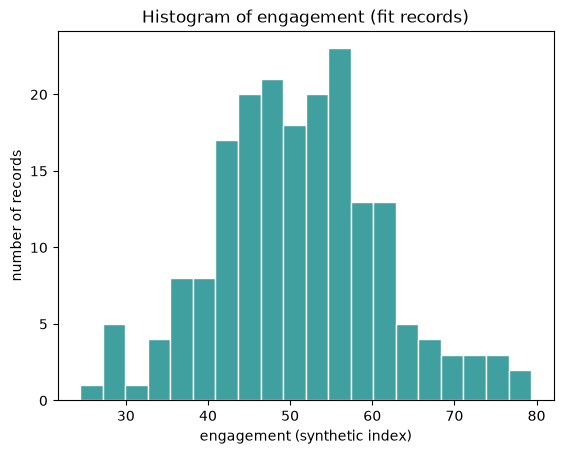

In [18]:
sns.histplot(eng, bins=20, color="teal", edgecolor="white")
plt.title("Histogram of engagement (fit records)")
plt.xlabel("engagement (synthetic index)")
plt.ylabel("number of records")
plt.savefig("outputs/figures/engagement_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

> **Interpretation :** The histogram is bell-shaped, with a slightly longer tail on the right but no extreme outliers.

### M2 — Welch t-test (G1 vs G2) and 95 % confidence interval

- **H0:** mean engagement of G1 = mean engagement of G2
- **H1:** mean engagement of G1 != mean engagement of G2  (two-sided, alpha = 0.05)

In [19]:
g1 = fit.loc[fit["group"] == "G1", "engagement"].dropna()
g2 = fit.loc[fit["group"] == "G2", "engagement"].dropna()
print("G1 count:", len(g1), "| G1 mean:", round(g1.mean(), 3))
print("G2 count:", len(g2), "| G2 mean:", round(g2.mean(), 3))

G1 count: 84 | G1 mean: 51.615
G2 count: 108 | G2 mean: 50.525


In [20]:
from scipy import stats

welch = stats.ttest_ind(g1, g2, equal_var=False)
print("t statistic:", round(welch.statistic, 4))
print("p-value    :", round(welch.pvalue, 4))


t statistic: 0.723
p-value    : 0.4707


In [21]:
ci_low, ci_high = stats.t.interval(0.95, 
                                   df=n_eng - 1, 
                                   loc=eng_mean, 
                                   scale=stats.sem(eng))

print("95% CI :", round(ci_low, 3), "to", round(ci_high, 3))

95% CI : 49.537 to 52.466


> **Interpretation** : The Welch test gives t = 0.72 and p = 0.47.
> Since p > 0.05 we fail to reject H0.

## M3 — Linear algebra: covariance matrix and eigenvalues

In [22]:
X = fit[["engagement", "visits"]].dropna().values  
n_rows = X.shape[0]
print("Rows used:", n_rows)

Rows used: 181


In [23]:
X_centered = X - X.mean(axis=0)

In [24]:
cov = X_centered.T @ X_centered / (n_rows - 1)
cov

array([[103.65708913,   4.11811311],
       [  4.11811311, 103.06117496]])

In [25]:
eigenvalues, eigenvectors = np.linalg.eigh(cov)
print("Eigenvalues:", eigenvalues.round(3))

Eigenvalues: [ 99.23  107.488]


In [26]:
largest_share = eigenvalues[-1] / eigenvalues.sum()
print("Largest eigenvalue / sum of eigenvalues:", round(largest_share, 4))

Largest eigenvalue / sum of eigenvalues: 0.52


>**Interpretation:** The largest eigenvalue (107.5) is 52 % of the total variance (the sum of eigenvalues).

# Task 2 — Preprocessing & Feature Engineering


In [27]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [28]:
num_cols = ["visits", "recency", "engagement", "spend"]
imputer = SimpleImputer(strategy="median")
imputer.fit(fit[num_cols])

,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['visits','recency','engagement','spend']"
indicator_ indicator_: :class:`~sklearn.impute.MissingIndicator`Indicator used to add binary indicators for missing values.`None` if `add_indicator=False`.,NoneType,None
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
"statistics_ statistics_: array of shape (n_features,)The imputation fill value for each feature.Computing statistics can result in `np.nan` values.During :meth:`transform`, features corresponding to `np.nan`statistics will be discarded.","ndarray[float64](4,)","[49.61,50.6 ,51.41,50.59]"


In [29]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)  
encoder.fit(fit[["group"]])

,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",False
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'ignore'
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",None
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infreque

In [30]:
fit_num = pd.DataFrame(imputer.transform(fit[num_cols]), columns=num_cols)
val_num = pd.DataFrame(imputer.transform(val[num_cols]), columns=num_cols)
test_num = pd.DataFrame(imputer.transform(test[num_cols]), columns=num_cols)

In [31]:
fit_num["engineered_feature"] = fit_num["engagement"] / (fit_num["recency"] + 1)
val_num["engineered_feature"] = val_num["engagement"] / (val_num["recency"] + 1)
test_num["engineered_feature"] = test_num["engagement"] / (test_num["recency"] + 1)

In [32]:
num_features = list(fit_num.columns)     
scaler = StandardScaler()
scaler.fit(fit_num)

StandardScaler()

### Apply the scaler 

In [33]:
fit_scaled = scaler.transform(fit_num)
val_scaled = scaler.transform(val_num)
test_scaled = scaler.transform(test_num)

In [34]:
fit_group = encoder.transform(fit[["group"]])
val_group = encoder.transform(val[["group"]])
test_group = encoder.transform(test[["group"]])

In [35]:
X_fit = np.hstack([fit_scaled, fit_group])
X_val = np.hstack([val_scaled, val_group])
X_test = np.hstack([test_scaled, test_group])

In [36]:
y_fit = fit["response"].values
y_val = val["response"].values
y_test = test["response"].values

In [37]:
feature_names = num_features + list(encoder.get_feature_names_out(["group"]))
feature_names

['visits',
 'recency',
 'engagement',
 'spend',
 'engineered_feature',
 'group_G1',
 'group_G2']

# Task 3 — Supervised Learning

In [38]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression


In [39]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_fit, y_fit)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](2,)","[0.43,0.57]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[int64](2,)","[0,1]"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,7
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


In [40]:
logreg = LogisticRegression(max_iter=1000, random_state=42)
logreg.fit(X_fit, y_fit)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [41]:
THRESHOLD = 0.5
base_pred = baseline.predict(X_test)

In [42]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, silhouette_score

In [43]:
base_accuracy = accuracy_score(y_test, base_pred)
base_precision = precision_score(y_test, base_pred)
base_recall = recall_score(y_test, base_pred)
base_f1 = f1_score(y_test, base_pred)

### Logistic regression: probabilities, then the 0.5 threshold

In [44]:
lr_prob = logreg.predict_proba(X_test)[:,1]
lr_pred = (lr_prob >= THRESHOLD).astype(int)

In [45]:
lr_accuracy = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred)
lr_recall = recall_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)

In [46]:
results = pd.DataFrame({
    "accuracy":  [base_accuracy, lr_accuracy],
    "precision": [base_precision, lr_precision],
    "recall":    [base_recall, lr_recall],
    "f1":        [base_f1, lr_f1],
}, index=["baseline", "logistic_regression"])
results.round(3)

,accuracy,precision,recall,f1
baseline,0.583,0.583,1.000,0.737
logistic_regression,0.817,0.833,0.857,0.845


In [47]:
lr_predictions = pd.DataFrame({
    "record_id": test["record_id"].values,
    "true_label": y_test,
    "predicted_label": lr_pred,
    "probability_class_1": lr_prob.round(6),
})
lr_predictions.to_csv("outputs/logreg_test_predictions.csv", index=False)
lr_predictions.head()

,record_id,true_label,predicted_label,probability_class_1
0,254,1,1,0.999949
1,88,0,0,0.299585
2,122,0,0,0.059920
3,8,0,1,0.996980
4,197,0,1,0.647045


In [48]:
print("Accuracy : baseline", round(base_accuracy, 3), "-> logistic regression", round(lr_accuracy, 3))
print("F1       : baseline", round(base_f1, 3), "-> logistic regression", round(lr_f1, 3))

Accuracy : baseline 0.583 -> logistic regression 0.817
F1       : baseline 0.737 -> logistic regression 0.845


> **Interpretation:**
>   Accuracy improves from 0.583 to 0.817 (+0.233) and F1 from 0.737 to 0.845 (+0.108). 

# Task 4 — Unsupervised Learning (K-Means)

In [49]:
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, silhouette_score

In [50]:
X_cluster = fit_scaled          
km2 = KMeans(n_clusters=2, n_init=10, random_state=42).fit(X_cluster)

In [51]:
km3 = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_cluster)

In [52]:
km4 = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X_cluster)

### Inertia and silhouette score for each k

In [54]:
k_scores = pd.DataFrame({
    "k": [2, 3, 4],
    "inertia": [km2.inertia_, km3.inertia_, km4.inertia_],
    "silhouette": [silhouette_score(X_cluster, km2.labels_),
                   silhouette_score(X_cluster, km3.labels_),
                   silhouette_score(X_cluster, km4.labels_)],
})

k_scores.to_csv("outputs/k_selection_scores.csv", index=False)
k_scores.round(4)

,k,inertia,silhouette
0,2,713.0304,0.2259
1,3,613.5511,0.1872
2,4,541.6453,0.1907


### Choose k (highest silhouette; a tie goes to the smaller k)

In [55]:
best_k = int(k_scores.loc[k_scores["silhouette"].idxmax(), "k"]) 

In [56]:
print("Chosen k:", best_k)

Chosen k: 2


> **Intpretation :**  The silhouette score is highest for k = 2 (0.226) compared with k = 3 (0.187) and k = 4 (0.191), so we choose k = 2. 

## Fit the chosen model and get each record's cluster

In [57]:
best_km = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit(X_cluster)
labels = best_km.labels_

In [58]:
# labels

In [59]:
profile = fit_num.copy()
profile["cluster"] = labels
cluster_profile = profile.groupby("cluster").mean().round(2)
cluster_profile["size"] = profile.groupby("cluster").size()
cluster_profile.to_csv("outputs/cluster_profiles.csv")
cluster_profile

,visits,recency,engagement,spend,engineered_feature,size
cluster,,,,,,
0,49.37,55.25,46.09,50.18,0.83,109
1,49.54,44.17,57.45,50.97,1.29,83


# Task 5 — Deep Learning up to ANN

In [66]:
import tensorflow as tf
from tensorflow import keras


[TensorFlow DLL Diagnostic] Analyzing: C:\Users\admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\tensorflow\python\_pywrap_tensorflow_internal.pyd
[Error] Failed to load _pywrap_tensorflow_common.dll: INITIALIZATION FAILED (0x45A) - The DLL's DllMain returned false.
    Hint: This often happens if your CPU lacks required instructions (like AVX/AVX2)
    or if the Microsoft Visual C++ Redistributable is outdated/missing.


ImportError: Traceback (most recent call last):
  File "C:\Users\admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\tensorflow\python\pywrap_tensorflow.py", line 74, in <module>
    from tensorflow.python._pywrap_tensorflow_internal import *
ImportError: DLL load failed while importing _pywrap_tensorflow_internal: A dynamic link library (DLL) initialization routine failed.


Failed to load the native TensorFlow runtime.
See https://www.tensorflow.org/install/errors for some common causes and solutions.
If you need help, create an issue at https://github.com/tensorflow/tensorflow/issues and include the entire stack trace above this error message.

In [64]:
ann = keras.Sequential()
ann.add(keras.layers.Input(shape=(X_fit.shape[1],))) 
ann.add(keras.layers.Dense(16, activation="relu"))
ann.add(keras.layers.Dense(8, activation="relu"))
ann.add(keras.layers.Dense(1, activation="sigmoid"))

NameError: name 'keras' is not defined

### Compile: Adam (learning rate 0.001) and binary cross-entropy

In [ ]:
ann.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
            loss="binary_crossentropy",
            metrics=["accuracy"])

In [ ]:
ann.summary()

In [ ]:
print("Trainable parameters:", ann.count_params())  

> **interpretation :**\
> The network is 7 → 16 (ReLU) → 8 (ReLU) → 1 (sigmoid).\
> Parameter count: (7×16+16) + (16×8+8) + (8×1+1) = 128 + 136 + 9 = 273 trainable parameters.

### Early stopping on validation loss (patience 5, restore best weights)

In [ ]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

In [ ]:
history = ann.fit(X_fit, y_fit,
                  validation_data=(X_val, y_val),
                  epochs=50, batch_size=16,
                  callbacks=[early_stop], verbose=0)

In [ ]:
epochs_run = len(history.history["loss"])
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print("Epochs actually run  :", epochs_run, "(maximum allowed = 50)")
print("Best epoch (restored):", best_epoch)

In [ ]:
plt.plot(history.history["loss"], label="training loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.title("ANN learning curves")
plt.xlabel("epoch")
plt.ylabel("binary cross-entropy loss")
plt.legend()
plt.savefig("outputs/figures/ann_loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()

> **Interpretation:** \
> Training ran for all 50 epochs (the maximum, seed 42), and the best epoch was epoch 50,\
> so early stopping never had to trigger (validation loss kept improving).\
> Both curves fall smoothly and stay close together, with no sign of overfitting

### Test the ANN once on the same 60 test records (threshold 0.5)

In [ ]:
ann_prob = ann.predict(X_test, verbose=0).ravel()
ann_pred = (ann_prob >= THRESHOLD).astype(int)

In [ ]:
ann_accuracy = accuracy_score(y_test, ann_pred)
ann_precision = precision_score(y_test, ann_pred, zero_division=0)
ann_recall = recall_score(y_test, ann_pred, zero_division=0)
ann_f1 = f1_score(y_test, ann_pred, zero_division=0)

### Compare all three models

In [ ]:
comparison = pd.DataFrame({
    "accuracy":  [base_accuracy, lr_accuracy, ann_accuracy],
    "precision": [base_precision, lr_precision, ann_precision],
    "recall":    [base_recall, lr_recall, ann_recall],
    "f1":        [base_f1, lr_f1, ann_f1],
}, index=["baseline", "logistic_regression", "ann"])
comparison.to_csv("outputs/metrics_comparison.csv")
comparison.round(3)

In [ ]:
ann_predictions = pd.DataFrame({
    "record_id": test["record_id"].values,
    "true_label": y_test,
    "predicted_label": ann_pred,
    "probability_class_1": ann_prob.round(6),
})
ann_predictions.to_csv("outputs/ann_test_predictions.csv", index=False)
ann_predictions.to_csv("models/ann_test_predictions.csv", index=False)

In [ ]:
ann.save("models/ann_model.keras")

**Interpretation (same 60 test records, threshold 0.5):**

| Model | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| Logistic regression | 0.817 | 0.833 | 0.857 | 0.845 |
| ANN | 0.833 | 0.838 | 0.886 | 0.861 |

The ANN's F1 is 0.016 higher, which is **one single test record**. On 60 records this is well within chance, so the two models perform **about the same**.
